# 03 — Gaussian Anomaly Detection | CIC-IDS2017 (Kaggle)

**Mục tiêu:** triển khai baseline thống kê phát hiện bất thường theo *binary* (`BENIGN = 0`, các nhãn tấn công `= 1`). Gaussian chỉ học từ **BENIGN trong tập train**; ngưỡng phát hiện được chọn **chỉ trên validation**; test chỉ được đánh giá một lần.

**Giới hạn phương pháp:** Dataset CSV thiếu timestamp/IP/flow ID, nên mẫu lấy theo nhãn và random split **không chống được event/host leakage**. Đây là **exploratory pilot**, **không** phải kết quả generalization cuối cùng. Những lớp hiếm cần thận trọng. Tách `Background` của CTU-13 không liên quan notebook này.

Notebook tự đọc 8 CSV từ Kaggle, không nén lại ZIP; lưu split/metrics/model vào `/kaggle/working/nids_outputs/03_Gaussian_Anomaly/`.

In [24]:
from pathlib import Path
import json, sys, os
import numpy as np
import pandas as pd

SEED = 42
PER_ATTACK_LABEL = 1000       # pilot; có thể tăng sau khi kiểm tra RAM
BENIGN_LIMIT = 5000          # giúp Gaussian có đủ train benign
CHUNK_SIZE = 100_000

OUTPUT = Path('/kaggle/working/nids_outputs/03_Gaussian_Anomaly')
OUTPUT.mkdir(parents=True, exist_ok=True)

candidates = sorted(Path('/kaggle/input').rglob('Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv'))
if not candidates:
    raise FileNotFoundError('Không tìm thấy 8 CSV CIC-IDS2017. Hãy Add Input nids-se-at-cnn-data.')
CIC_DIR = candidates[0].parent
FILES = sorted(CIC_DIR.glob('*.csv'))
assert len(FILES) == 8, f'Expected 8 CIC CSV, found {len(FILES)} in {CIC_DIR}'

# Có thể dùng source đã được copy bởi notebook 00; hoặc source dataset trực tiếp.
roots = [Path('/kaggle/working/NIDS-SE-AT-CNN')]
roots += [p.parent.parent.parent for p in Path('/kaggle/input').rglob('src/nids/models.py')]
ROOT = next((p for p in roots if (p/'src/nids/models.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Không thấy src/nids/models.py. Hãy Add Input source và chạy bước copy source từ notebook 00.')
sys.path.insert(0, str(ROOT / 'src'))

from nids.datasets import CIC_FEATURES
from nids.models import DiagonalGaussian

print('Project:', ROOT)
print('CIC directory:', CIC_DIR)
print('CSV count:', len(FILES))
print('Feature count:', len(CIC_FEATURES))
print('Output:', OUTPUT)

Project: /kaggle/working/NIDS-SE-AT-CNN
CIC directory: /kaggle/input/datasets/chienvoo/nids-se-at-cnn-data/CIC-IDS2017
CSV count: 8
Feature count: 19
Output: /kaggle/working/nids_outputs/03_Gaussian_Anomaly


## 1. Lấy mẫu theo nhãn từ CSV (không giải nén thêm)

Sử dụng **priority reservoir sampling**: gán khóa ngẫu nhiên độc lập cho từng dòng, chỉ giữ các khóa nhỏ nhất theo nhãn. Cách này giữ bộ nhớ giới hạn theo số mẫu mong muốn, không tải toàn bộ 2,83 triệu dòng lên RAM. Đây là mẫu pilot, không đại diện cho phân phối lớp thực tế.

In [25]:
from collections import Counter

rng = np.random.default_rng(SEED)
kept = {}
source_counts = Counter()
feature_names = list(CIC_FEATURES)

for path in FILES:
    # CIC CSV có thể có khoảng trắng đầu tên cột.
    header = pd.read_csv(path, nrows=0, encoding='latin1').columns
    col_map = {str(c).strip(): c for c in header}
    needed = feature_names + ['Label']
    missing = [c for c in needed if c not in col_map]
    if missing:
        raise ValueError(f'{path.name}: thiếu cột {missing}')
    selected = [col_map[c] for c in needed]
    rows_seen = 0
    for chunk in pd.read_csv(path, usecols=selected, chunksize=CHUNK_SIZE,
                             encoding='latin1', low_memory=False):
        chunk.columns = chunk.columns.str.strip()
        chunk['Label'] = chunk['Label'].astype('string').str.strip()
        chunk = chunk.loc[chunk['Label'].notna() & (chunk['Label'] != '')].copy()
        rows_seen += len(chunk)
        source_counts.update(chunk['Label'].value_counts().to_dict())
        chunk['_priority'] = rng.random(len(chunk))
        for label, group in chunk.groupby('Label', sort=False):
            label = str(label)
            limit = BENIGN_LIMIT if label == 'BENIGN' else PER_ATTACK_LABEL
            candidate = group.nsmallest(limit, '_priority')
            if label in kept:
                candidate = pd.concat([kept[label], candidate], ignore_index=True)
            kept[label] = candidate.nsmallest(limit, '_priority').reset_index(drop=True)
    print(f'{path.name}: {rows_seen:,} flows')

sample = pd.concat([part.drop(columns='_priority') for part in kept.values()], ignore_index=True)
sample = sample.sample(frac=1, random_state=SEED).reset_index(drop=True)
print(f'Full flows scanned: {sum(source_counts.values()):,}')
print(f'Pilot sampled flows: {len(sample):,}')
print('Pilot counts:')
print(sample['Label'].value_counts().to_string())
assert sample['Label'].eq('BENIGN').any() and sample['Label'].ne('BENIGN').any()

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv: 225,745 flows
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv: 286,467 flows
Friday-WorkingHours-Morning.pcap_ISCX.csv: 191,033 flows
Monday-WorkingHours.pcap_ISCX.csv: 529,918 flows
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv: 288,602 flows
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv: 170,366 flows
Tuesday-WorkingHours.pcap_ISCX.csv: 445,909 flows
Wednesday-workingHours.pcap_ISCX.csv: 692,703 flows
Full flows scanned: 2,830,743
Pilot sampled flows: 15,720
Pilot counts:
Label
BENIGN                          5000
DoS Hulk                        1000
Web Attack ï¿½ Brute Force      1000
DoS Slowhttptest                1000
Bot                             1000
DoS GoldenEye                   1000
DDoS                            1000
PortScan                        1000
SSH-Patator                     1000
FTP-Patator                     1000
DoS slowloris                   1000
Web Attack ï¿½ XSS            

## 2. Chia tập cố định — không dùng test để fit hoặc tune

`_split` được lưu theo từng dòng của mẫu pilot. Các notebook baseline tiếp theo có thể dùng đúng **cùng split artifact** (và giữ nguyên class mapping) để so sánh. Các bước imputation/scaling được fit sau khi chia tập.

In [26]:
from sklearn.model_selection import train_test_split

labels = sample['Label'].astype(str)
y = (labels != 'BENIGN').astype(np.int8).to_numpy()
all_idx = np.arange(len(sample))
train_idx, hold_idx = train_test_split(all_idx, test_size=0.40,
                                     random_state=SEED, stratify=y)
val_idx, test_idx = train_test_split(hold_idx, test_size=0.50,
                                   random_state=SEED, stratify=y[hold_idx])

split = np.empty(len(sample), dtype=object)
split[train_idx] = 'train'
split[val_idx] = 'validation'
split[test_idx] = 'test'
sample['_split'] = split
sample['_binary_label'] = y

# Lưu sample/split dùng chung; chưa điền giá trị thiếu để model tự fit preprocessing trên train.
split_path = OUTPUT / 'cic_pilot_splits.parquet'
sample.to_parquet(split_path, index=False)
print('Saved shared split:', split_path)
print(pd.crosstab(sample['_split'], sample['_binary_label'], rownames=['split'], colnames=['attack=1']))

# Chú ý: split theo binary chứ không stratify theo đủ 15 nhãn; lớp hiếm có thể biến mất ở val/test.
print('Rare classes by split:')
rare = labels.value_counts()[lambda s: s < 50].index
print(pd.crosstab(sample.loc[labels.isin(rare),'Label'], sample.loc[labels.isin(rare),'_split']))

Saved shared split: /kaggle/working/nids_outputs/03_Gaussian_Anomaly/cic_pilot_splits.parquet
attack=1       0     1
split                 
test        1000  2144
train       3000  6432
validation  1000  2144
Rare classes by split:
_split                        test  train  validation
Label                                                
Heartbleed                       2      6           3
Infiltration                     9     18           9
Web Attack ï¿½ Sql Injection     7     10           4


## 3. Preprocessing — fit trên BENIGN TRAIN **duy nhất**

Chuyển feature về số, thay ±Inf bằng NaN, fit median imputer và StandardScaler trên benign train. Điều này tránh để mẫu tấn công tác động đến tham số mô hình bất thường. Các phép biến đổi tương tự áp dụng cho validation/test. Một số feature có thể có giá trị cực trị; kiểm tra tỷ lệ NaN/Inf trước khi fit.

In [27]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

X = sample[feature_names].apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan)
X = X.astype('float64')
X = X.replace([np.inf, -np.inf], np.nan)
print('NaN/non-numeric feature cells:', int(X.isna().sum().sum()))

benign_train_mask = (split == 'train') & (y == 0)
assert benign_train_mask.sum() >= 20, 'Benign TRAIN too small'

preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
    ('scaler', StandardScaler()),
])
preprocessor.fit(X.loc[benign_train_mask])

x_train_benign = preprocessor.transform(X.loc[benign_train_mask])
x_val = preprocessor.transform(X.iloc[val_idx])
x_test = preprocessor.transform(X.iloc[test_idx])
assert np.isfinite(x_train_benign).all() and np.isfinite(x_val).all() and np.isfinite(x_test).all()
print('Benign train:', x_train_benign.shape)
print('Validation:', x_val.shape)
print('Test:', x_test.shape)

NaN/non-numeric feature cells: 38
Benign train: (3000, 19)
Validation: (3144, 19)
Test: (3144, 19)


## 4. Fit Gaussian; chọn ngưỡng bằng validation và đánh giá trên test

`DiagonalGaussian.score_samples` trả score lớn hơn cho điểm phù hợp phân phối normal; ta đổi sang **anomaly score = −score** (lớn hơn → bất thường). F1 threshold được chọn bằng validation, test không tham gia chọn ngưỡng.

In [28]:
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report)

model = DiagonalGaussian().fit(x_train_benign)
val_anomaly = -np.asarray(model.score_samples(x_val), dtype=float)
assert np.isfinite(val_anomaly).all()

# Không lấy quantile score rồi giả định lớp; trực tiếp chọn threshold trên validation.
# Thêm ngưỡng cao hơn max: mô hình có thể dự đoán tất cả benign.
candidate_thresholds = np.r_[np.unique(np.quantile(val_anomaly, np.linspace(0, 1, 501))),
                             np.nextafter(val_anomaly.max(), np.inf)]
val_truth = y[val_idx]
val_f1s = np.array([f1_score(val_truth, val_anomaly >= t, zero_division=0)
                   for t in candidate_thresholds])
selected = int(np.argmax(val_f1s))
threshold = float(candidate_thresholds[selected])
print('Chosen threshold (validation only):', threshold)
print('Validation F1:', round(float(val_f1s[selected]), 5))

test_truth = y[test_idx]
test_anomaly = -np.asarray(model.score_samples(x_test), dtype=float)
test_pred = (test_anomaly >= threshold).astype(int)
cm = confusion_matrix(test_truth, test_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
metrics = {
    'accuracy': float(accuracy_score(test_truth, test_pred)),
    'precision_attack': float(precision_score(test_truth, test_pred, zero_division=0)),
    'recall_attack': float(recall_score(test_truth, test_pred, zero_division=0)),
    'f1_attack': float(f1_score(test_truth, test_pred, zero_division=0)),
    'fpr': float(fp / max(fp + tn, 1)),
    'roc_auc': float(roc_auc_score(test_truth, test_anomaly)) if len(set(test_truth)) == 2 else None,
    'average_precision': float(average_precision_score(test_truth, test_anomaly)) if len(set(test_truth)) == 2 else None,
    'validation_f1': float(val_f1s[selected]),
    'threshold': threshold,
    'n_train_benign': int(benign_train_mask.sum()),
    'n_validation': int(len(val_idx)),
    'n_test': int(len(test_idx)),
    'protocol': 'STRATIFIED_BINARY_RANDOM_EXPLORATORY_PILOT_NOT_LEAKAGE_SAFE',
    'feature_count': len(feature_names),
    'seed': SEED,
}

print(json.dumps(metrics, indent=2))
print('Confusion Matrix [BENIGN=0, ATTACK=1]:', cm)
print(classification_report(test_truth, test_pred,
                            labels=[0,1], target_names=['BENIGN','ATTACK'], zero_division=0))

Chosen threshold (validation only): 11.327006367698537
Validation F1: 0.86311
{
  "accuracy": 0.7878498727735369,
  "precision_attack": 0.7811191473163304,
  "recall_attack": 0.957089552238806,
  "f1_attack": 0.8601970236847621,
  "fpr": 0.575,
  "roc_auc": 0.6899766791044777,
  "average_precision": 0.8235824325144944,
  "validation_f1": 0.8631138975966562,
  "threshold": 11.327006367698537,
  "n_train_benign": 3000,
  "n_validation": 3144,
  "n_test": 3144,
  "protocol": "STRATIFIED_BINARY_RANDOM_EXPLORATORY_PILOT_NOT_LEAKAGE_SAFE",
  "feature_count": 19,
  "seed": 42
}
Confusion Matrix [BENIGN=0, ATTACK=1]: [[ 425  575]
 [  92 2052]]
              precision    recall  f1-score   support

      BENIGN       0.82      0.42      0.56      1000
      ATTACK       0.78      0.96      0.86      2144

    accuracy                           0.79      3144
   macro avg       0.80      0.69      0.71      3144
weighted avg       0.79      0.79      0.76      3144



## 5. Lưu artifact + trực quan hóa

Lưu **cả imputer, scaler, mô hình Gaussian, threshold, feature schema** để sử dụng lại đúng cách. Những đánh giá ở đây chỉ phản ánh pilot ngẫu nhiên có rủi ro leakage.

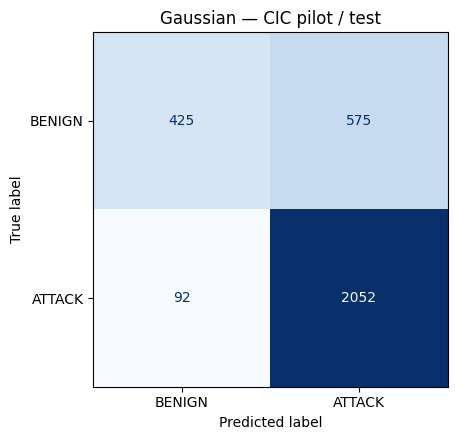

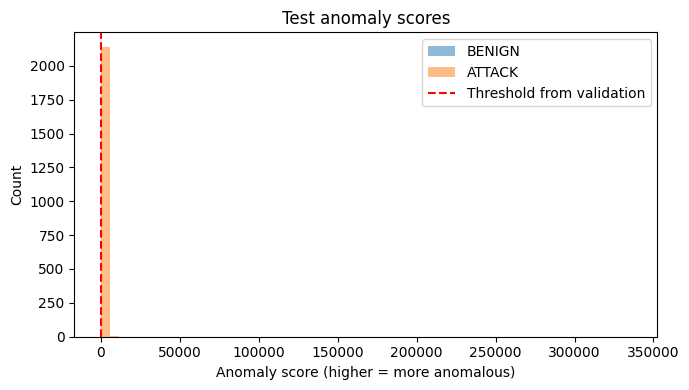

Saved outputs:
 - anomaly_scores.png (44.6 KB)
 - cic_pilot_splits.parquet (765.5 KB)
 - confusion_matrix.png (27.4 KB)
 - gaussian_metrics.json (0.5 KB)
 - gaussian_pilot.joblib (3.2 KB)
 - test_classification_report.json (0.6 KB)


In [29]:
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay

joblib.dump({'preprocessor': preprocessor, 'gaussian': model, 'threshold': threshold,
             'features': feature_names, 'binary_mapping': {'BENIGN':0, 'ATTACK':1},
             'protocol': metrics['protocol']}, OUTPUT/'gaussian_pilot.joblib')
(OUTPUT/'gaussian_metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
(OUTPUT/'test_classification_report.json').write_text(json.dumps(
    classification_report(test_truth, test_pred, labels=[0,1],
                          target_names=['BENIGN','ATTACK'], output_dict=True, zero_division=0), indent=2),
    encoding='utf-8')

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=['BENIGN', 'ATTACK']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Gaussian — CIC pilot / test')
fig.tight_layout()
fig.savefig(OUTPUT/'confusion_matrix.png', dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
for name, mask in [('BENIGN', test_truth==0), ('ATTACK', test_truth==1)]:
    ax.hist(test_anomaly[mask], bins=60, alpha=0.5, label=name)
ax.axvline(threshold, color='red', linestyle='--', label='Threshold from validation')
ax.set(xlabel='Anomaly score (higher = more anomalous)', ylabel='Count', title='Test anomaly scores')
ax.legend(); fig.tight_layout()
fig.savefig(OUTPUT/'anomaly_scores.png', dpi=160)
plt.show()

print('Saved outputs:')
for p in sorted(OUTPUT.iterdir()):
    print(' -', p.name, f'({p.stat().st_size / 1024:.1f} KB)')